# TA-EVRP Visualization

Builds a `dronesim.ta_evrp.Instance` and runs the EVRP planner from a TA-EVRP config file.

Shows:
1. **Network** — road graph topology and connectivity
2. **Sampled problem** — depot, customers, and AFS overlaid on the graph
3. **Distance matrix** — inter-node distances heatmap
4. **Traffic model** — per-edge speed profiles (when PSL is enabled)
5. **Routes** — planned vehicle routes from the EVRP planner

In [1]:
CONFIG_PATH = "config/ta_evrp/milp.yaml"   # ← change this to any ta_evrp config

In [2]:
import os
import sys

os.chdir("/home/shinobi-owl/PhD/battery/DroneSim")
sys.path.insert(0, ".")

import yaml
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
from pathlib import Path

print("Working directory:", os.getcwd())

Working directory: /home/shinobi-owl/PhD/battery/DroneSim


## Load config and build Instance

In [3]:
def _deep_merge(base: dict, override: dict) -> dict:
    result = dict(base)
    for k, v in override.items():
        if k in result and isinstance(result[k], dict) and isinstance(v, dict):
            result[k] = _deep_merge(result[k], v)
        else:
            result[k] = v
    return result


with open(CONFIG_PATH) as f:
    child = yaml.safe_load(f)
base_path = child.pop("base", None)
if base_path:
    with open(base_path) as f:
        base_cfg = yaml.safe_load(f)
    ta_config = _deep_merge(base_cfg, child)
else:
    ta_config = child

print(f"Config loaded from : {CONFIG_PATH}")
print(f"Network            : {ta_config['network']['net_path']}")
print(f"Planner            : {ta_config['evrp']['planner']}")
print(f"TRSP agent         : {ta_config.get('trsp', {}).get('agent', 'dijkstra')}")
print(f"Traffic (PSL)      : enabled={ta_config.get('traffic', {}).get('psl', {}).get('enabled', False)}")

Config loaded from : config/ta_evrp/milp.yaml
Network            : data/ames/ames_campus_final.sumocfg
Planner            : milp
TRSP agent         : dijkstra
Traffic (PSL)      : enabled=True


In [4]:
from dronesim.ta_evrp import Instance

inst = Instance(ta_config)

print(f"net_xml_path : {inst.net_xml_path}")
print(f"nodes / edges: {inst.num_nodes} / {inst.num_edges}")
print(f"traffic      : enabled={inst.traffic_enabled}  K={inst.traffic.K}")
print(f"depot        : {inst.problem.depot_id}")
print(f"customers    : {len(inst.problem.customer_ids)}  → {inst.problem.customer_ids}")
print(f"AFS          : {len(inst.problem.afs_ids)}  → {inst.problem.afs_ids}")
print(f"dist matrix  : {inst.problem.physical_dist.shape}")

net_xml_path : /home/shinobi-owl/PhD/battery/DroneSim/data/ames/ames_campus_final.net.xml
nodes / edges: 28 / 80
traffic      : enabled=True  K=2
depot        : 11105893597
customers    : 10  → ['cluster_10781666531_10781666539_1454602029_2010155933', 'cluster_161156577_161156691', 'cluster9127991351_9127991358_9127991361_9127991367_#5more', '161132183', '1756935507', '161160292', '2449733006', 'cluster_161125851_1756110631', '161035628', '161156565']
AFS          : 3  → ['cluster_161136333_161136435', '161163571', '161132162']
dist matrix  : (14, 14)


---
## 1  Network graph

In [5]:
G   = inst.graph
pos = inst.network.node_positions

print(f"Nodes             : {G.number_of_nodes()}")
print(f"Edges             : {G.number_of_edges()}")
print(f"Weakly connected  : {nx.is_weakly_connected(G)}")
print(f"Strongly connected: {nx.is_strongly_connected(G)}")

in_deg  = sorted(dict(G.in_degree()).values(),  reverse=True)
out_deg = sorted(dict(G.out_degree()).values(), reverse=True)
print(f"In-degree  max/mean: {in_deg[0]} / {np.mean(in_deg):.2f}")
print(f"Out-degree max/mean: {out_deg[0]} / {np.mean(out_deg):.2f}")

Nodes             : 28
Edges             : 80
Weakly connected  : True
Strongly connected: True
In-degree  max/mean: 4 / 2.86
Out-degree max/mean: 4 / 2.86


/home/shinobi-owl/anaconda3/envs/clean_rl_2/lib/python3.10/site-packages/IPython/core/pylabtools.py:77: DeprecationWarning: backend2gui is deprecated since IPython 8.24, backends are managed in matplotlib and can be externally registered.
  warnings.warn(


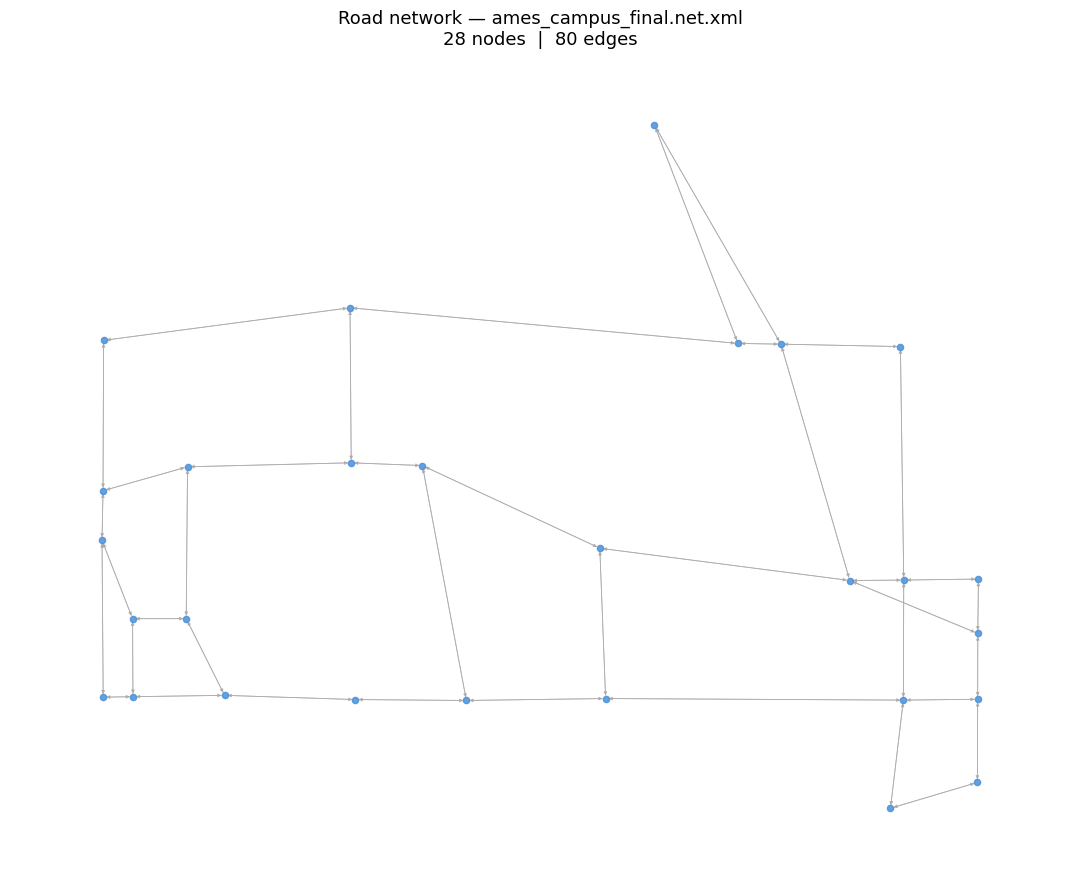

In [6]:
fig, ax = plt.subplots(figsize=(12, 9))

nx.draw_networkx(
    G,
    pos=pos,
    ax=ax,
    node_size=20,
    node_color="#4a90d9",
    edge_color="#aaaaaa",
    width=0.6,
    alpha=0.85,
    with_labels=False,
    arrows=True,
    arrowsize=5,
)

ax.set_title(
    f"Road network — {Path(inst.net_xml_path).name}\n"
    f"{G.number_of_nodes()} nodes  |  {G.number_of_edges()} edges",
    fontsize=13,
)
ax.set_aspect("equal")
ax.axis("off")
plt.tight_layout()
plt.show()

---
## 2  Sampled problem — depot, customers, AFS

In [7]:
prob = inst.problem

print(f"{'Node':<6}{'Type':<12}SUMO ID")
print("-" * 60)
for name, ntype, sid in zip(prob.node_names, prob.node_types, prob.physical_meta["physical_sumo_ids"]):
    print(f"{name:<6}{ntype:<12}{sid}")

print()
p = prob.params
print(f"Fleet params:")
print(f"  m (vehicles)     : {p['m']}")
print(f"  Q (range, m)     : {p['Q']:.1f}")
print(f"  speed (m/s)      : {p['speed']:.2f}  ({p['speed']*3.6:.1f} km/h)")
print(f"  Tmax (s)         : {p['Tmax']:.0f}  ({p['Tmax']/3600:.2f} h)")
print(f"  service time (s) : {p['customer_service_time']:.1f}")
print(f"  refuel time  (s) : {p['refuel_time']:.1f}")

Node  Type        SUMO ID
------------------------------------------------------------
D     depot       11105893597
C1    customer    cluster_10781666531_10781666539_1454602029_2010155933
C2    customer    cluster_161156577_161156691
C3    customer    cluster9127991351_9127991358_9127991361_9127991367_#5more
C4    customer    161132183
C5    customer    1756935507
C6    customer    161160292
C7    customer    2449733006
C8    customer    cluster_161125851_1756110631
C9    customer    161035628
C10   customer    161156565
F1    afs         cluster_161136333_161136435
F2    afs         161163571
F3    afs         161132162

Fleet params:
  m (vehicles)     : 3
  Q (range, m)     : 15000.0
  speed (m/s)      : 30.56  (110.0 km/h)
  Tmax (s)         : 21600  (6.00 h)
  service time (s) : 0.0
  refuel time  (s) : 0.0


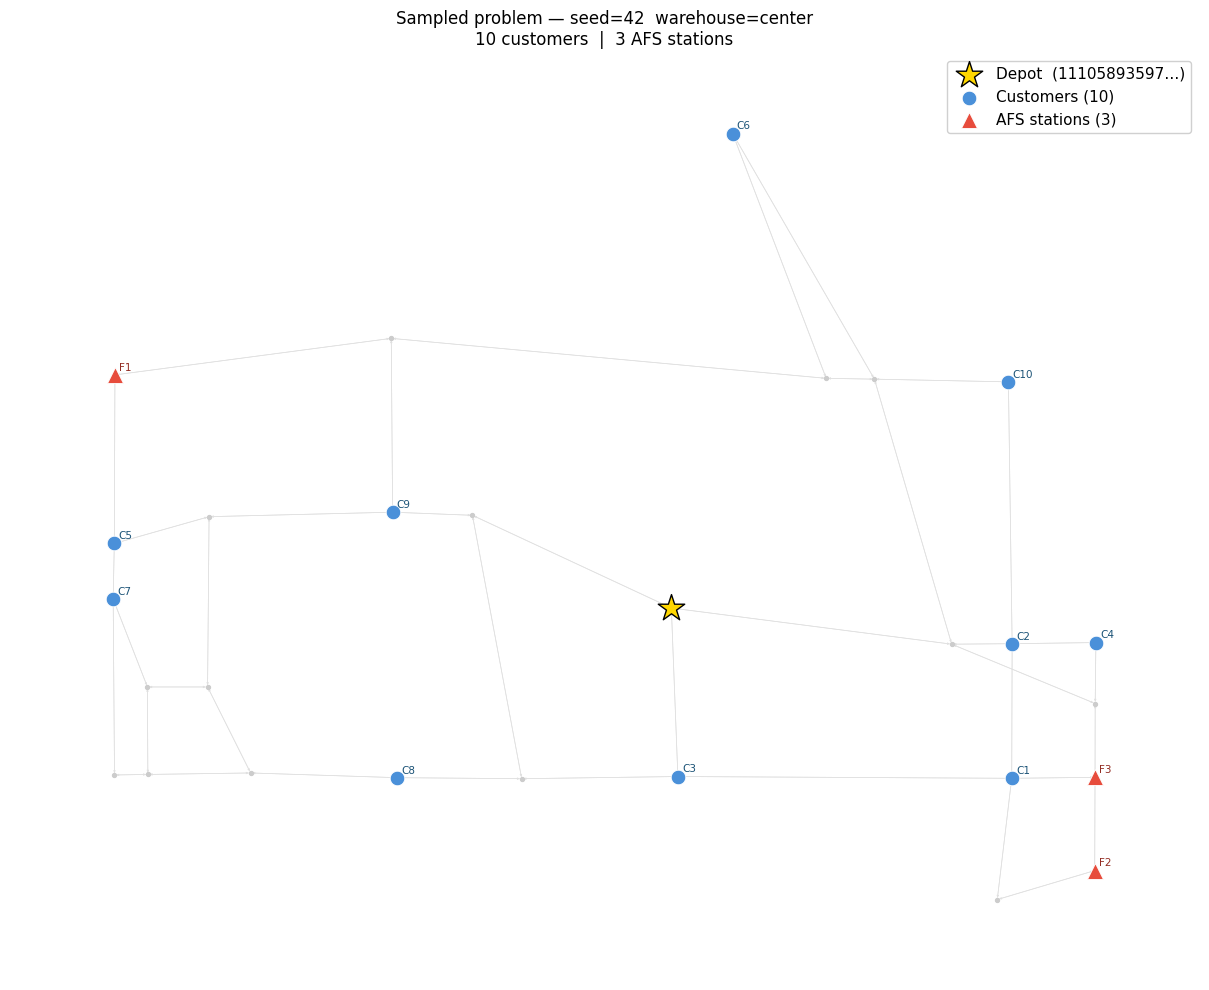

In [8]:
fig, ax = plt.subplots(figsize=(13, 10))

# Base graph (faded)
nx.draw_networkx(
    G,
    pos=pos,
    ax=ax,
    node_size=8,
    node_color="#cccccc",
    edge_color="#e0e0e0",
    width=0.5,
    alpha=1.0,
    with_labels=False,
    arrows=True,
    arrowsize=3,
)

# Depot
depot_xy = pos[prob.depot_id]
ax.scatter(*depot_xy, s=400, marker="*", color="gold", edgecolors="black",
           linewidths=1.0, zorder=6, label=f"Depot  ({prob.depot_id[:16]}…)")

# Customers
c_xs = [pos[cid][0] for cid in prob.customer_ids if cid in pos]
c_ys = [pos[cid][1] for cid in prob.customer_ids if cid in pos]
ax.scatter(c_xs, c_ys, s=110, marker="o", color="#4a90d9", edgecolors="white",
           linewidths=0.6, zorder=5, label=f"Customers ({len(prob.customer_ids)})")

for i, cid in enumerate(prob.customer_ids):
    if cid in pos:
        ax.annotate(f"C{i+1}", xy=pos[cid], xytext=(3, 3), textcoords="offset points",
                    fontsize=7.5, color="#1a5276", zorder=7)

# AFS
a_xs = [pos[aid][0] for aid in prob.afs_ids if aid in pos]
a_ys = [pos[aid][1] for aid in prob.afs_ids if aid in pos]
ax.scatter(a_xs, a_ys, s=130, marker="^", color="#e74c3c", edgecolors="white",
           linewidths=0.6, zorder=5, label=f"AFS stations ({len(prob.afs_ids)})")

for i, aid in enumerate(prob.afs_ids):
    if aid in pos:
        ax.annotate(f"F{i+1}", xy=pos[aid], xytext=(3, 3), textcoords="offset points",
                    fontsize=7.5, color="#922b21", zorder=7)

ax.legend(fontsize=11, framealpha=0.92, loc="best")
ax.set_title(
    f"Sampled problem — seed={ta_config.get('generation_seed', 42)}"
    f"  warehouse={ta_config['network'].get('warehouse', 'center')}\n"
    f"{len(prob.customer_ids)} customers  |  {len(prob.afs_ids)} AFS stations",
    fontsize=12,
)
ax.set_aspect("equal")
ax.axis("off")
plt.tight_layout()
plt.show()

---
## 3  Distance matrix

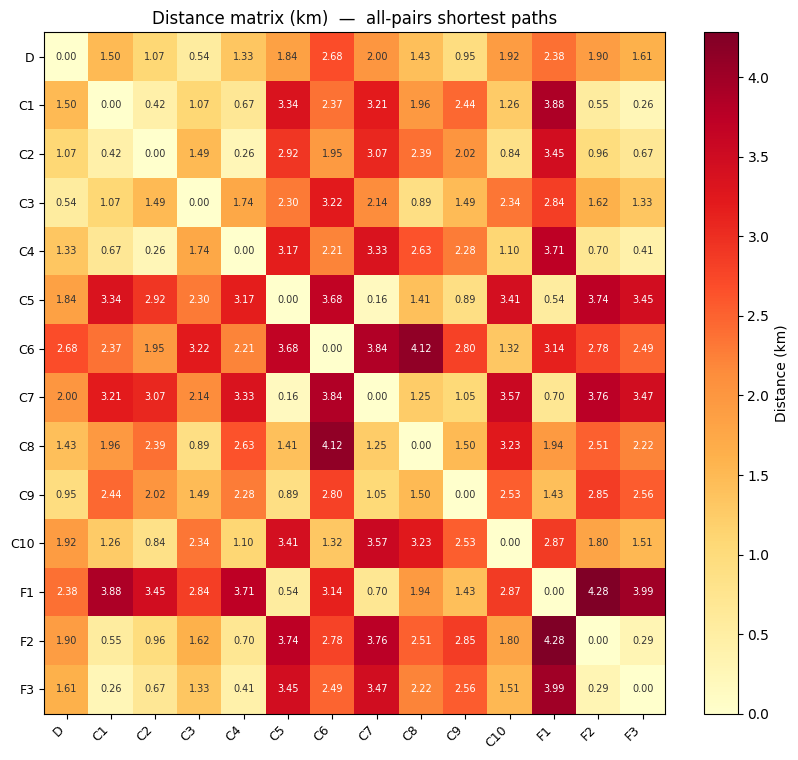

Distance stats (km):  min=0.159  mean=2.079  max=4.282


In [9]:
dist_km = prob.physical_dist / 1000.0
labels  = prob.node_names
n       = len(labels)

fig, ax = plt.subplots(figsize=(max(6, n * 0.6), max(5, n * 0.55)))

im = ax.imshow(dist_km, cmap="YlOrRd", aspect="auto")
plt.colorbar(im, ax=ax, label="Distance (km)")

ax.set_xticks(range(n))
ax.set_yticks(range(n))
ax.set_xticklabels(labels, rotation=45, ha="right", fontsize=9)
ax.set_yticklabels(labels, fontsize=9)

thresh = dist_km.max() / 2.0
for i in range(n):
    for j in range(n):
        val = dist_km[i, j]
        color = "white" if val > thresh else "#333333"
        ax.text(j, i, f"{val:.2f}", ha="center", va="center",
                fontsize=7, color=color)

ax.set_title("Distance matrix (km)  —  all-pairs shortest paths", fontsize=12)
plt.tight_layout()
plt.show()

off_diag = dist_km[dist_km > 0]
print(f"Distance stats (km):  min={off_diag.min():.3f}  mean={off_diag.mean():.3f}  max={off_diag.max():.3f}")

---
## 4  Traffic model

In [10]:
tm = inst.traffic

print(f"Traffic model enabled : {tm.enabled}")
print(f"K (time slots)        : {tm.K}")
print(f"delta_t (s/slot)      : {tm.delta_t:.1f}  ({tm.delta_t/60:.1f} min)")
print(f"free_flow speed       : {tm.free_flow_ms:.2f} m/s  ({tm.free_flow_ms*3.6:.1f} km/h)")
if tm.enabled:
    speeds_flat = np.array([v for vlist in tm.profiles.values() for v in vlist])
    print(f"Speed range           : {speeds_flat.min()*3.6:.1f} – {speeds_flat.max()*3.6:.1f} km/h")
    print(f"Unique speed levels   : {sorted(set(round(s*3.6, 1) for s in speeds_flat))} km/h")
    print(f"Edges with profiles   : {len(tm.profiles)}")

Traffic model enabled : True
K (time slots)        : 2
delta_t (s/slot)      : 300.0  (5.0 min)
free_flow speed       : 30.56 m/s  (110.0 km/h)
Speed range           : 40.0 – 100.0 km/h
Unique speed levels   : [40.0, 100.0] km/h
Edges with profiles   : 80


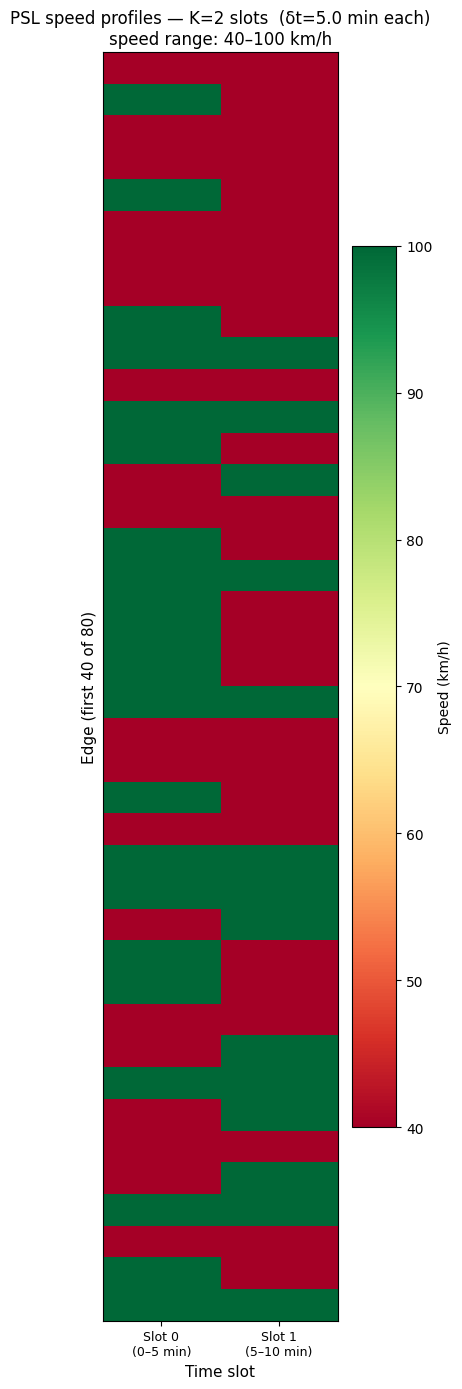

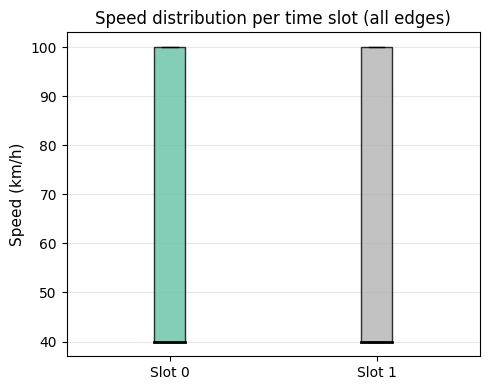

/tmp/ipykernel_126150/4008360716.py:100: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


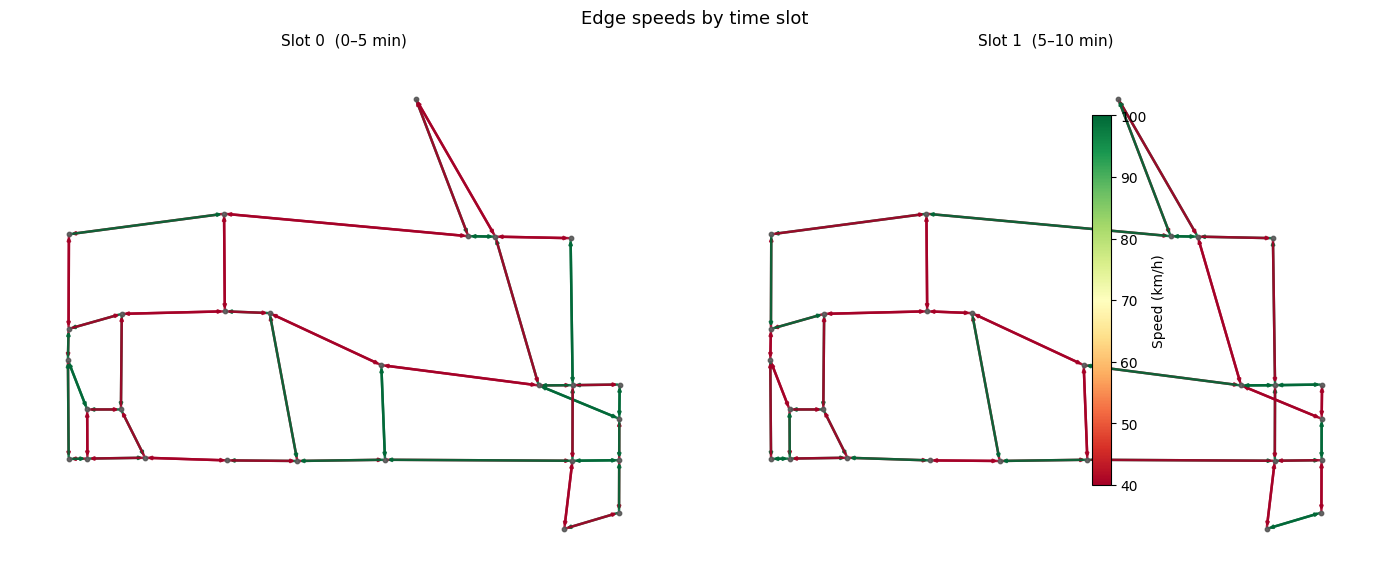

In [11]:
if not tm.enabled:
    print(f"Traffic disabled — all edges run at free-flow speed: {tm.free_flow_ms*3.6:.1f} km/h")
else:
    edge_ids = list(tm.profiles.keys())

    # --- 4a: speed heatmap (edges × slots) ---
    speed_matrix = np.array(
        [[tm.get_speed(eid, k) * 3.6 for k in range(tm.K)] for eid in edge_ids]
    )  # shape: (n_edges, K)  in km/h

    n_show = min(len(edge_ids), 40)   # cap at 40 edges for readability
    fig, ax = plt.subplots(figsize=(max(4, tm.K * 1.2), max(6, n_show * 0.35)))

    im = ax.imshow(speed_matrix[:n_show], cmap="RdYlGn", aspect="auto",
                   vmin=tm.v_min * 3.6, vmax=tm.v_max * 3.6)
    plt.colorbar(im, ax=ax, label="Speed (km/h)")

    ax.set_xlabel("Time slot", fontsize=11)
    ax.set_ylabel(f"Edge (first {n_show} of {len(edge_ids)})", fontsize=11)
    ax.set_xticks(range(tm.K))
    ax.set_xticklabels([f"Slot {k}\n({k*tm.delta_t/60:.0f}–{(k+1)*tm.delta_t/60:.0f} min)" for k in range(tm.K)], fontsize=9)
    ax.set_yticks([])
    ax.set_title(
        f"PSL speed profiles — K={tm.K} slots  (δt={tm.delta_t/60:.1f} min each)\n"
        f"speed range: {tm.v_min*3.6:.0f}–{tm.v_max*3.6:.0f} km/h",
        fontsize=12,
    )
    plt.tight_layout()
    plt.show()

    # --- 4b: speed distribution per slot ---
    fig, ax = plt.subplots(figsize=(max(5, tm.K * 2.5), 4))

    slot_labels = [f"Slot {k}" for k in range(tm.K)]
    all_speeds_kmh = [speed_matrix[:, k] for k in range(tm.K)]

    bplot = ax.boxplot(
        all_speeds_kmh,
        labels=slot_labels,
        patch_artist=True,
        medianprops=dict(color="black", linewidth=2),
    )
    palette = plt.colormaps.get_cmap("Set2")
    for patch, k in zip(bplot["boxes"], range(tm.K)):
        patch.set_facecolor(palette(k / max(tm.K - 1, 1)))
        patch.set_alpha(0.8)

    ax.set_ylabel("Speed (km/h)", fontsize=11)
    ax.set_title("Speed distribution per time slot (all edges)", fontsize=12)
    ax.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

    # --- 4c: edge speed coloring on network graph ---
    if tm.K >= 1:
        fig, axes = plt.subplots(1, min(tm.K, 3), figsize=(min(tm.K, 3) * 7, 6), squeeze=False)

        v_min_kmh = tm.v_min * 3.6
        v_max_kmh = tm.v_max * 3.6
        cmap = plt.colormaps.get_cmap("RdYlGn")
        norm = mcolors.Normalize(vmin=v_min_kmh, vmax=v_max_kmh)

        for k in range(min(tm.K, 3)):
            ax = axes[0][k]
            edge_color_map = {}
            for u, v, data in G.edges(data=True):
                eid = data.get("id", "")
                spd = tm.get_speed(eid, k) * 3.6 if eid in tm.profiles else tm.free_flow_ms * 3.6
                edge_color_map[(u, v)] = cmap(norm(spd))

            edge_list   = list(G.edges())
            edge_colors = [edge_color_map.get(e, cmap(norm(tm.free_flow_ms * 3.6))) for e in edge_list]

            nx.draw_networkx(
                G,
                pos=pos,
                ax=ax,
                node_size=10,
                node_color="#555555",
                edgelist=edge_list,
                edge_color=edge_colors,
                width=1.8,
                alpha=0.9,
                with_labels=False,
                arrows=True,
                arrowsize=4,
            )
            ax.set_title(
                f"Slot {k}  ({k*tm.delta_t/60:.0f}–{(k+1)*tm.delta_t/60:.0f} min)",
                fontsize=11,
            )
            ax.set_aspect("equal")
            ax.axis("off")

        # shared colorbar
        sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
        sm.set_array([])
        fig.colorbar(sm, ax=axes[0], label="Speed (km/h)", shrink=0.8)
        fig.suptitle("Edge speeds by time slot", fontsize=13)
        plt.tight_layout()
        plt.show()

---
## Summary

In [12]:
print("=" * 55)
print(f"Config           : {CONFIG_PATH}")
print(f"Network          : {Path(inst.net_xml_path).name}")
print(f"  Nodes/edges    : {inst.num_nodes} / {inst.num_edges}")
print(f"  Strongly conn. : {nx.is_strongly_connected(inst.graph)}")
print()
print(f"Problem (seed={ta_config.get('generation_seed', 42)})")
print(f"  Fleet size     : {inst.problem.params['m']}")
print(f"  Customers      : {len(inst.problem.customer_ids)}")
print(f"  AFS stations   : {len(inst.problem.afs_ids)}")
print(f"  Range Q        : {inst.problem.params['Q']/1000:.1f} km")
print(f"  Max duration   : {inst.problem.params['Tmax']/3600:.1f} h")
print()
print(f"Traffic          : {'PSL enabled' if inst.traffic_enabled else 'disabled (free-flow)'}")
if inst.traffic_enabled:
    print(f"  K slots        : {inst.traffic.K}")
    print(f"  Slot duration  : {inst.traffic.delta_t/60:.1f} min")
    print(f"  Speed range    : {inst.traffic.v_min*3.6:.0f}–{inst.traffic.v_max*3.6:.0f} km/h")
else:
    print(f"  Free-flow speed: {inst.traffic.free_flow_ms*3.6:.1f} km/h")
print("=" * 55)

Config           : config/ta_evrp/milp.yaml
Network          : ames_campus_final.net.xml
  Nodes/edges    : 28 / 80
  Strongly conn. : True

Problem (seed=42)
  Fleet size     : 3
  Customers      : 10
  AFS stations   : 3
  Range Q        : 15.0 km
  Max duration   : 6.0 h

Traffic          : PSL enabled
  K slots        : 2
  Slot duration  : 5.0 min
  Speed range    : 40–100 km/h


---
## 5  Routes

Runs the EVRP planner on the instance above and visualises the planned vehicle routes.

In [13]:
from dronesim.ta_evrp.planner import GlobalPlanner

gp     = GlobalPlanner()
routes = gp.plan(inst)   # MILP may take a few seconds

Q_m  = inst.problem.params["Q"]
prob = inst.problem

print(f"Planner  : {inst.planner_name}")
print(f"Vehicles : {len(routes)}")
print()
print(f"{'Veh':<5}{'Stops':<7}{'Customers':<12}{'AFS visits':<12}{'Duration (h)':<15}{'Dist (km)'}")
print("-" * 65)
for r in routes:
    dur_h = r.stops[-1].planned_time / 3600.0
    # distance ≈ total fuel consumed across legs (r=1 ⟹ consumption = distance)
    dist_m = 0.0
    for i in range(len(r.stops) - 1):
        si = r.stops[i]
        sj = r.stops[i + 1]
        dep_fuel = Q_m if si.node_type in {"depot", "afs", "afs_dummy", "depot_dummy"} else si.planned_fuel
        dist_m  += max(dep_fuel - sj.planned_fuel, 0.0)
    print(f"{r.vehicle_id:<5}{len(r.stops):<7}{len(r.customer_stops):<12}{len(r.afs_stops):<12}{dur_h:<15.3f}{dist_m / 1000:.2f}")

Set parameter Username
Set parameter LicenseID to value 2810942
Academic license - for non-commercial use only - expires 2027-04-20
Set parameter TimeLimit to value 300
Set parameter OutputFlag to value 1
Set parameter MIPGap to value 0.01
Gurobi Optimizer version 13.0.1 build v13.0.1rc0 (linux64 - "Ubuntu 24.04.4 LTS")

CPU model: Intel(R) Core(TM) i9-14900HX, instruction set [SSE2|AVX|AVX2]
Thread count: 32 physical cores, 32 logical processors, using up to 32 threads

Non-default parameters:
TimeLimit  300
MIPGap  0.01

Optimize a model with 961 rows, 654 columns and 4396 nonzeros (Min)
Model fingerprint: 0x9487d615
Model has 602 linear objective coefficients
Variable types: 52 continuous, 602 integer (602 binary)
Coefficient statistics:
  Matrix range     [1e+00, 2e+04]
  Objective range  [2e+02, 4e+03]
  Bounds range     [1e+00, 2e+04]
  RHS range        [1e+00, 2e+04]

Presolve removed 250 rows and 17 columns
Presolve time: 0.02s
Presolved: 711 rows, 637 columns, 7401 nonzeros
Va

In [14]:
for r in routes:
    print(f"\n{'─' * 68}")
    print(f"  Vehicle {r.vehicle_id}  ({len(r.stops)} stops)")
    print(f"{'─' * 68}")
    print(f"  {'#':<4}{'Node':<12}{'Type':<14}{'Fuel (m)':<12}{'Fuel (%Q)':<11}{'Time (h)'}")
    print(f"  {'─' * 60}")
    for i, s in enumerate(r.stops):
        pct = 100.0 * s.planned_fuel / Q_m
        t_h = s.planned_time / 3600.0
        print(f"  {i:<4}{s.node_name:<12}{s.node_type:<14}{s.planned_fuel:<12.1f}{pct:<11.1f}{t_h:.3f}")


────────────────────────────────────────────────────────────────────
  Vehicle 1  (13 stops)
────────────────────────────────────────────────────────────────────
  #   Node        Type          Fuel (m)    Fuel (%Q)  Time (h)
  ────────────────────────────────────────────────────────────
  0   D           depot         15000.0     100.0      0.000
  1   C9          customer      14052.9     93.7       0.009
  2   C5          customer      13159.0     87.7       0.017
  3   C7          customer      12999.6     86.7       0.018
  4   C8          customer      11753.5     78.4       0.030
  5   C3          customer      10860.8     72.4       0.038
  6   C1          customer      9788.7      65.3       0.047
  7   F3_d2       afs_dummy     15000.0     100.0      0.050
  8   C4          customer      14588.4     97.3       0.053
  9   C2          customer      14329.3     95.5       0.056
  10  C10         customer      13486.9     89.9       0.063
  11  C6          customer      12169.4

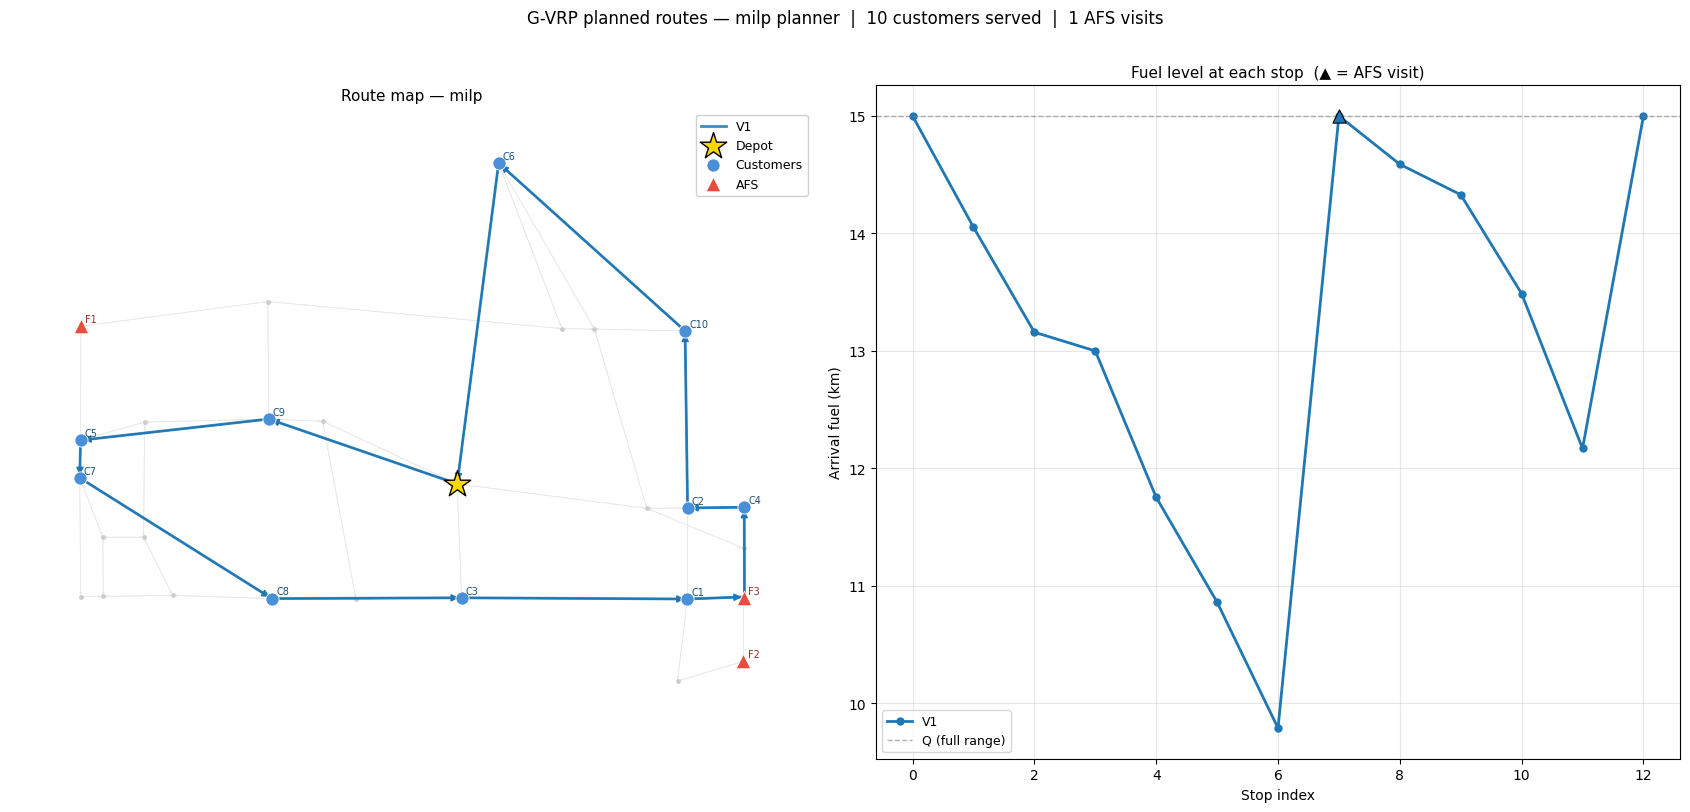

In [15]:
import math
from collections import defaultdict

fig, axes = plt.subplots(1, 2, figsize=(17, 8))
palette   = plt.colormaps.get_cmap("tab10")

# ── Left: route map overlaid on road network ─────────────────────────────────
ax1 = axes[0]
nx.draw_networkx(
    G, pos=pos, ax=ax1,
    node_size=6, node_color="#cccccc", edge_color="#e8e8e8",
    width=0.5, alpha=1.0, with_labels=False, arrows=True, arrowsize=3,
)

_dummy_count = defaultdict(int)

def _stop_xy(stop):
    base = pos.get(stop.sumo_node_id, (0.0, 0.0))
    if stop.node_type in {"afs_dummy", "depot_dummy"}:
        _dummy_count[stop.sumo_node_id] += 1
        k   = _dummy_count[stop.sumo_node_id]
        ang = 2.0 * math.pi * k / 6.0
        return (base[0] + 8.0 * math.cos(ang), base[1] + 8.0 * math.sin(ang))
    return (float(base[0]), float(base[1]))

for ridx, route in enumerate(routes):
    color  = palette(ridx % 10)
    coords = [_stop_xy(s) for s in route.stops]
    xs = [c[0] for c in coords]
    ys = [c[1] for c in coords]
    ax1.plot(xs, ys, color=color, linewidth=2.0, alpha=0.85,
             label=f"V{route.vehicle_id}", zorder=2)
    for i in range(len(coords) - 1):
        ax1.annotate(
            "", xy=coords[i + 1], xytext=coords[i],
            arrowprops=dict(arrowstyle="-|>", color=color, lw=1.3, mutation_scale=10),
            zorder=3,
        )

_dummy_count.clear()

# Problem nodes
ax1.scatter(*pos[prob.depot_id], s=400, marker="*", color="gold",
            edgecolors="black", linewidths=1.0, zorder=6, label="Depot")
c_xs = [pos[cid][0] for cid in prob.customer_ids if cid in pos]
c_ys = [pos[cid][1] for cid in prob.customer_ids if cid in pos]
ax1.scatter(c_xs, c_ys, s=90, marker="o", color="#4a90d9",
            edgecolors="white", linewidths=0.6, zorder=5, label="Customers")
for i, cid in enumerate(prob.customer_ids):
    if cid in pos:
        ax1.annotate(f"C{i+1}", xy=pos[cid], xytext=(3, 3),
                     textcoords="offset points", fontsize=7, color="#1a5276", zorder=7)
a_xs = [pos[aid][0] for aid in prob.afs_ids if aid in pos]
a_ys = [pos[aid][1] for aid in prob.afs_ids if aid in pos]
ax1.scatter(a_xs, a_ys, s=110, marker="^", color="#e74c3c",
            edgecolors="white", linewidths=0.6, zorder=5, label="AFS")
for i, aid in enumerate(prob.afs_ids):
    if aid in pos:
        ax1.annotate(f"F{i+1}", xy=pos[aid], xytext=(3, 3),
                     textcoords="offset points", fontsize=7, color="#922b21", zorder=7)

ax1.legend(fontsize=9, framealpha=0.9, loc="best")
ax1.set_title(f"Route map — {inst.planner_name}", fontsize=11)
ax1.set_aspect("equal")
ax1.axis("off")

# ── Right: fuel level at each stop ───────────────────────────────────────────
ax2 = axes[1]
for ridx, route in enumerate(routes):
    color    = palette(ridx % 10)
    fuel_km  = [s.planned_fuel / 1000.0 for s in route.stops]
    ax2.plot(range(len(fuel_km)), fuel_km, color=color, linewidth=2.0,
             marker="o", markersize=5, label=f"V{route.vehicle_id}", zorder=2)
    # highlight AFS stops (refuel point)
    for i, s in enumerate(route.stops):
        if s.node_type in {"afs", "afs_dummy"}:
            ax2.scatter(i, fuel_km[i], s=90, marker="^", color=color,
                        edgecolors="black", linewidths=0.8, zorder=4)

ax2.axhline(Q_m / 1000.0, color="grey", linestyle="--", linewidth=1.0,
            alpha=0.6, label="Q (full range)")
ax2.set_xlabel("Stop index", fontsize=10)
ax2.set_ylabel("Arrival fuel (km)", fontsize=10)
ax2.set_title("Fuel level at each stop  (▲ = AFS visit)", fontsize=11)
ax2.legend(fontsize=9)
ax2.grid(alpha=0.3)

plt.suptitle(
    f"G-VRP planned routes — {inst.planner_name} planner  |  "
    f"{sum(len(r.customer_stops) for r in routes)} customers served  |  "
    f"{sum(len(r.afs_stops) for r in routes)} AFS visits",
    fontsize=12, y=1.01,
)
plt.tight_layout()
plt.show()